# Qu'est-ce qui pousse un client à annuler sa réservation d'hôtel ?

**Projet d'analyse de données — Raphaël Collard**
Dossier d'entrée à la formation Data Analyst (OpenClassrooms)

**Données** : dataset *Hotel Booking Demand* (Kaggle), 119 390 réservations et 32 colonnes. Il couvre deux hôtels, un hôtel de ville (*City Hotel*) et un hôtel de vacances (*Resort Hotel*), pour des arrivées entre juillet 2015 et août 2017.

**Question** : quels facteurs sont liés à l'annulation d'une réservation, et quelles recommandations concrètes peut-on en tirer pour un hôtel ?

**Plan**
1. Import et découverte des données
2. Nettoyage : valeurs manquantes, doublons, valeurs aberrantes
3. Analyse univariée
4. Analyse bivariée : chaque variable croisée avec `is_canceled`
5. Conclusion et recommandations

*Le fichier `hotel_bookings.csv` doit se trouver dans le même dossier que ce notebook.*

## 1. Import et découverte des données

In [55]:
import pandas as pd                          # manipulation des tableaux de données
import matplotlib.pyplot as plt              # graphiques
from scipy.stats import chi2_contingency     # test du Chi-2 (analyse bivariée)

data = pd.read_csv('hotel_bookings.csv')     # chargement du dataset
print(data.shape)                            # dimensions : (lignes, colonnes)
data.head()                                  # aperçu des 5 premières lignes

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [56]:
data.info()   # type de chaque colonne et nombre de valeurs renseignées

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

Le dataset contient 119 390 réservations et 32 colonnes. La variable à expliquer est `is_canceled` : 1 = réservation annulée, 0 = réservation honorée.

## 2. Nettoyage
### 2.1 Valeurs manquantes

In [57]:
data.isnull().sum()   # nombre de valeurs manquantes par colonne

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

Quatre colonnes ont des valeurs manquantes : `children` (4), `country` (488), `agent` (16 340) et `company` (112 593, soit 94,3 %).

In [58]:
data['children'] = data['children'].fillna(0)        # 4 valeurs manquantes : remplacées par 0 enfant
data['country'] = data['country'].fillna('Inconnu')  # pays non renseigné : remplacé par 'Inconnu'

In [59]:
data[data['agent'].isnull()].sample(1)   # à quoi ressemble une réservation sans agent ?

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
31922,Resort Hotel,0,74,2017,January,2,9,1,2,1,...,No Deposit,NaN,NaN,0,Transient,30.0,0,1,Check-Out,2017-01-12


In [60]:
data['agent'] = data['agent'].fillna(0)   # valeur manquante = réservation sans agent : remplacée par 0

Pour `company`, 94,3 % des valeurs manquent. Avant de supprimer la colonne, je vérifie si le fait d'avoir une entreprise renseignée est lié à l'annulation : si c'est le cas, la supprimer ferait perdre une information utile.

In [61]:
# Nouvelle colonne plus lisible : la réservation est-elle liée à une entreprise ?
data['a_une_company'] = data['company'].notnull().map({True: 'Company', False: 'Sans company'})
data.groupby('a_une_company')['is_canceled'].mean()   # taux d'annulation dans chaque groupe

a_une_company
Company         0.175224
Sans company    0.382200
Name: is_canceled, dtype: float64

Les réservations liées à une entreprise sont annulées à 17,5 %, contre 38,2 % sans entreprise, soit plus de deux fois moins. L'information est utile : je garde la colonne.

### 2.2 Doublons

In [62]:
data.duplicated().sum()   # nombre de lignes strictement identiques à une autre

np.int64(31994)

31 994 lignes sont en double. Sans numéro de réservation ni nom de client, impossible de savoir s'il s'agit d'erreurs ou de réservations différentes qui ont les mêmes caractéristiques. Je les garde.

**Recommandation pour l'hôtel** : ajouter un identifiant unique à chaque réservation.

### 2.3 Valeurs aberrantes

In [63]:
data[(data['adults'] == 0) & (data['children'] == 0) & (data['babies'] == 0)]   # réservations sans aucun client

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,a_une_company
2224,Resort Hotel,0,1,2015,October,41,6,0,3,0,...,0.0,174.0,0,Transient-Party,0.00,0,0,Check-Out,2015-10-06,Company
2409,Resort Hotel,0,0,2015,October,42,12,0,0,0,...,0.0,174.0,0,Transient,0.00,0,0,Check-Out,2015-10-12,Company
3181,Resort Hotel,0,36,2015,November,47,20,1,2,0,...,38.0,NaN,0,Transient-Party,0.00,0,0,Check-Out,2015-11-23,Sans company
3684,Resort Hotel,0,165,2015,December,53,30,1,4,0,...,308.0,NaN,122,Transient-Party,0.00,0,0,Check-Out,2016-01-04,Sans company
3708,Resort Hotel,0,165,2015,December,53,30,2,4,0,...,308.0,NaN,122,Transient-Party,0.00,0,0,Check-Out,2016-01-05,Sans company
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115029,City Hotel,0,107,2017,June,26,27,0,3,0,...,7.0,NaN,0,Transient,100.80,0,0,Check-Out,2017-06-30,Sans company
115091,City Hotel,0,1,2017,June,26,30,0,1,0,...,0.0,NaN,0,Transient,0.00,1,1,Check-Out,2017-07-01,Sans company
116251,City Hotel,0,44,2017,July,28,15,1,1,0,...,425.0,NaN,0,Transient,73.80,0,0,Check-Out,2017-07-17,Sans company
116534,City Hotel,0,2,2017,July,28,15,2,5,0,...,9.0,NaN,0,Transient-Party,22.86,0,1,Check-Out,2017-07-22,Sans company


180 réservations n'ont ni adulte, ni enfant, ni bébé : 0,15 % du dataset. C'est anecdotique et sans impact sur l'analyse, je les laisse.

In [64]:
data['adr'].describe()   # résumé statistique du prix moyen par nuit (adr)

count    119390.000000
mean        101.831122
std          50.535790
min          -6.380000
25%          69.290000
50%          94.575000
75%         126.000000
max        5400.000000
Name: adr, dtype: float64

Le prix moyen par nuit va de -6,38 € à 5 400 €, pour une moyenne de 101,8 €. Les deux extrêmes méritent une vérification.

In [65]:
data[data['adr'] < 0]   # réservations à prix négatif

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,a_une_company
14969,Resort Hotel,0,195,2017,March,10,5,4,6,2,...,273.0,NaN,0,Transient-Party,-6.38,0,0,Check-Out,2017-03-15,Sans company


In [66]:
data = data[data['adr'] >= 0]   # une seule réservation concernée, erreur évidente : supprimée

In [67]:
data[data['adr'] > 3000]   # réservations au-dessus de 3 000 € la nuit

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,a_une_company
48515,City Hotel,1,35,2016,March,13,25,0,1,2,...,12.0,NaN,0,Transient,5400.0,0,0,Canceled,2016-02-19,Sans company


Une seule réservation dépasse 3 000 € (5 400 € la nuit), et elle est annulée : c'est une valeur aberrante isolée, je la supprime.

In [68]:
data = data[data['adr'] < 3000]   # suppression de la réservation à 5 400 €
data.shape                        # vérification : 2 lignes supprimées au total

(119388, 33)

In [69]:
data.describe()   # résumé de toutes les colonnes numériques

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119388.000000,119388.000000,119388.000000,119388.000000,119388.000000,119388.000000,119388.000000,119388.000000,119388.000000,119388.000000,119388.000000,119388.000000,119388.000000,119388.000000,119388.000000,6797.000000,119388.000000,119388.000000,119388.000000,119388.000000
mean,0.370414,104.011232,2016.156548,27.165435,15.798254,0.927581,2.500285,1.856401,0.103888,0.007949,0.031904,0.087119,0.137082,0.221103,74.827185,189.266735,2.321188,101.787650,0.062519,0.571372
std,0.482918,106.863481,0.707478,13.605100,8.780807,0.998579,1.908270,0.579266,0.398558,0.097437,0.175746,0.844343,1.497440,0.652287,107.141161,131.655015,17.594866,48.152738,0.245293,0.792802
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,152.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,510.000000,8.000000,5.000000


Le maximum atteint 55 adultes, 10 enfants et 10 bébés dans une même réservation : je vérifie ces valeurs.

In [70]:
data[data['adults'] > 4]   # réservations de plus de 4 adultes

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,a_une_company
1539,Resort Hotel,1,304,2015,September,36,3,0,3,40,...,0.0,NaN,0,Group,0.0,0,0,Canceled,2015-01-02,Sans company
1587,Resort Hotel,1,333,2015,September,36,5,2,5,26,...,96.0,NaN,0,Group,0.0,0,0,Canceled,2015-01-02,Sans company
1643,Resort Hotel,1,336,2015,September,37,7,1,2,50,...,0.0,NaN,0,Group,0.0,0,0,Canceled,2015-01-18,Sans company
1752,Resort Hotel,1,340,2015,September,37,12,2,5,26,...,96.0,NaN,0,Group,0.0,0,0,Canceled,2015-01-02,Sans company
1884,Resort Hotel,1,347,2015,September,38,19,2,5,26,...,96.0,NaN,0,Group,0.0,0,0,Canceled,2015-01-02,Sans company
1917,Resort Hotel,1,349,2015,September,39,21,1,3,27,...,0.0,NaN,0,Group,0.0,0,0,Canceled,2015-01-02,Sans company
1962,Resort Hotel,1,352,2015,September,39,24,1,3,27,...,0.0,NaN,0,Group,0.0,0,0,Canceled,2015-01-02,Sans company
2003,Resort Hotel,1,354,2015,September,39,26,2,5,26,...,96.0,NaN,0,Group,0.0,0,0,Canceled,2015-01-02,Sans company
2164,Resort Hotel,1,361,2015,October,40,3,2,5,26,...,96.0,NaN,0,Group,0.0,0,0,Canceled,2015-01-02,Sans company
2173,Resort Hotel,1,338,2015,October,41,4,2,0,55,...,0.0,NaN,0,Group,0.0,0,0,Canceled,2015-01-02,Sans company


16 réservations (0,01 %). Elles sont toutes de type Group et toutes annulées : cela ressemble à de vraies réservations de groupe, pas à des erreurs. Je les garde.

In [71]:
data[(data['babies'] > 2) | (data['children'] > 3)][['adults', 'children', 'babies', 'customer_type']]   # familles très nombreuses

,adults,children,babies,customer_type
328,2,10.0,0,Contract
46619,2,0.0,10,Transient
78656,1,0.0,9,Transient-Party


Trois réservations. La première (2 adultes et 10 enfants) reste possible. Les deux autres (1 ou 2 adultes avec 9 ou 10 bébés) sont très probablement des erreurs de saisie : je les supprime.

In [72]:
data = data[data['babies'] < 9]   # suppression des 2 réservations avec 9 et 10 bébés
data.shape                        # dimensions finales après nettoyage

(119386, 33)

**Bilan du nettoyage** : 119 386 réservations conservées, soit 4 lignes supprimées. Les valeurs manquantes ont été remplacées (`children`, `country`, `agent`) ou exploitées (`company`).

## 3. Analyse univariée
Chaque variable est d'abord étudiée seule, pour poser le décor avant de la croiser avec les annulations.

### Variable cible : `is_canceled`

In [73]:
data['is_canceled'].value_counts(normalize=True)   # part des réservations honorées (0) et annulées (1)

is_canceled
0    0.62958
1    0.37042
Name: proportion, dtype: float64

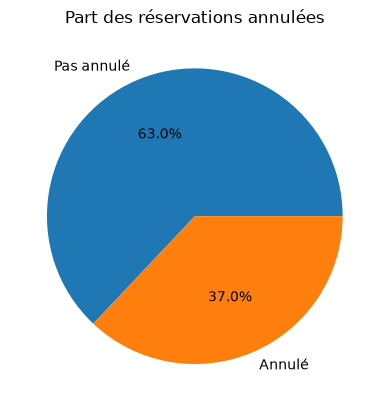

In [74]:
repartition = data['is_canceled'].value_counts(normalize=True)             # proportions honorées / annulées
plt.pie(repartition, labels=['Pas annulé', 'Annulé'], autopct='%1.1f%%')   # autopct affiche le % sur chaque part
plt.title("Part des réservations annulées")
plt.show()

**37 % des réservations sont annulées**, plus d'une sur trois. C'est un enjeu important pour un hôtel.

### `hotel`

In [75]:
data['hotel'].value_counts()   # nombre de réservations par hôtel

hotel
City Hotel      79327
Resort Hotel    40059
Name: count, dtype: int64

Le dataset concerne deux hôtels : City Hotel (environ 2/3 des réservations) et Resort Hotel (environ 1/3).

### `lead_time` : nombre de jours entre la réservation et l'arrivée

In [76]:
data['lead_time'].describe()

count    119386.000000
mean        104.012573
std         106.863861
min           0.000000
25%          18.000000
50%          69.000000
75%         160.000000
max         737.000000
Name: lead_time, dtype: float64

Le délai va de 0 jour (réservation le jour même) à 737 jours (plus de deux ans à l'avance). La moyenne (104 jours) est tirée vers le haut par les réservations très anticipées : la médiane (69 jours) représente mieux un comportement typique. Rien d'aberrant, je garde toutes les valeurs.

### `adr` : prix moyen par nuit

In [77]:
data['adr'].describe()   # prix après nettoyage

count    119386.000000
mean        101.787852
std          48.153112
min           0.000000
25%          69.290000
50%          94.575000
75%         126.000000
max         510.000000
Name: adr, dtype: float64

Après nettoyage, les prix vont de 0 € à 510 €. Je vérifie les réservations à 0 €.

In [78]:
data[data['adr'] == 0]   # réservations à 0 € la nuit

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,a_une_company
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,0.0,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,Sans company
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,0.0,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,Sans company
125,Resort Hotel,0,32,2015,July,27,4,0,1,4,...,0.0,NaN,0,Transient,0.0,0,1,Check-Out,2015-07-05,Sans company
167,Resort Hotel,0,111,2015,July,28,6,0,0,2,...,240.0,NaN,0,Transient,0.0,0,2,Check-Out,2015-07-06,Sans company
168,Resort Hotel,0,0,2015,July,28,6,0,0,1,...,250.0,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-06,Sans company
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118631,City Hotel,0,78,2017,August,34,23,0,0,1,...,98.0,NaN,0,Transient-Party,0.0,0,0,Check-Out,2017-08-23,Sans company
118762,City Hotel,0,1,2017,August,34,24,0,1,2,...,0.0,NaN,0,Transient,0.0,0,3,Check-Out,2017-08-25,Sans company
118963,City Hotel,0,1,2017,August,35,27,0,0,2,...,0.0,NaN,0,Transient,0.0,0,0,Check-Out,2017-08-27,Sans company
119102,City Hotel,0,518,2017,August,34,26,2,1,1,...,229.0,NaN,0,Transient-Party,0.0,0,0,Check-Out,2017-08-29,Sans company


In [79]:
zero_adr = data[data['adr'] == 0]                          # uniquement les réservations à 0 €
zero_adr['reservation_status'].value_counts(normalize=True)   # sont-elles allées jusqu'au bout du séjour ?

reservation_status
Check-Out    0.891271
Canceled     0.095457
No-Show      0.013272
Name: proportion, dtype: float64

1 959 réservations sont à 0 €, et 89 % d'entre elles sont allées jusqu'au check-out. Ce ne sont donc pas des erreurs de saisie, plutôt des gratuités ou des offres promotionnelles : je les garde.

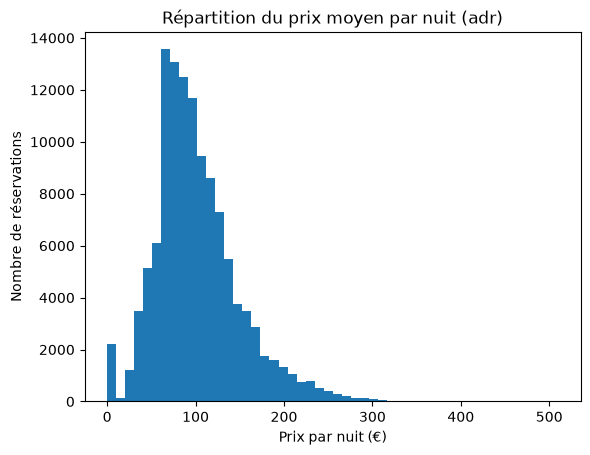

In [80]:
plt.hist(data['adr'], bins=50)   # répartition des prix par nuit
plt.title("Répartition du prix moyen par nuit (adr)")
plt.xlabel("Prix par nuit (€)")
plt.ylabel("Nombre de réservations")
plt.show()

La distribution est cohérente : la moitié des réservations se situe entre 69 € et 126 € la nuit.

### `deposit_type` : type de dépôt

In [81]:
data['deposit_type'].value_counts(normalize=True) * 100   # répartition en %

deposit_type
No Deposit    87.646793
Non Refund    12.217513
Refundable     0.135694
Name: proportion, dtype: float64

87,6 % des réservations sont faites sans dépôt, 12,2 % avec un dépôt non remboursable et 0,14 % avec un dépôt remboursable.

**Hypothèse** : les réservations payées d'avance et non remboursables devraient être très peu annulées. Je le vérifierai en bivariée.

### `customer_type` : type de client

In [82]:
data['customer_type'].value_counts(normalize=True) * 100

customer_type
Transient          75.059890
Transient-Party    21.042668
Contract            3.414136
Group               0.483306
Name: proportion, dtype: float64

Plus de 95 % des clients sont des clients de passage : Transient (client individuel, 75 %) et Transient-Party (21 %). Les contrats (3,4 %) et les groupes (0,5 %) sont minoritaires.

### `market_segment` : canal de réservation

In [83]:
data['market_segment'].value_counts(normalize=True) * 100

market_segment
Online TA        47.305379
Offline TA/TO    20.285461
Groups           16.593235
Direct           10.559027
Corporate         4.434356
Complementary     0.622351
Aviation          0.198516
Undefined         0.001675
Name: proportion, dtype: float64

67 % des réservations passent par une agence de voyage : en ligne (Online TA, 47 %) ou hors ligne / tour-opérateurs (Offline TA/TO, 20 %). Les groupes représentent 17 %.

### `total_of_special_requests` : nombre de demandes spéciales

In [84]:
data['total_of_special_requests'].value_counts(normalize=True) * 100

total_of_special_requests
0    58.897191
1    27.829896
2    10.863083
3     2.091535
4     0.284791
5     0.033505
Name: proportion, dtype: float64

59 % des réservations n'ont aucune demande spéciale (étage élevé, lits séparés…). Je vérifierai en bivariée si les clients qui en font annulent moins.

### Durée du séjour : `stays_in_weekend_nights` et `stays_in_week_nights`

In [85]:
data['stays_in_weekend_nights'].describe()   # nombre de nuits de week-end

count    119386.000000
mean          0.927579
std           0.998579
min           0.000000
25%           0.000000
50%           1.000000
75%           2.000000
max          19.000000
Name: stays_in_weekend_nights, dtype: float64

In [86]:
data['stays_in_week_nights'].describe()      # nombre de nuits en semaine

count    119386.000000
mean          2.500302
std           1.908280
min           0.000000
25%           1.000000
50%           2.000000
75%           3.000000
max          50.000000
Name: stays_in_week_nights, dtype: float64

In [87]:
data[data['stays_in_weekend_nights'] > 10][['stays_in_weekend_nights', 'stays_in_week_nights']]   # les très longs séjours

,stays_in_weekend_nights,stays_in_week_nights
1655,13,33
3820,12,30
3850,12,30
9839,16,40
14037,18,42
14038,19,50
32589,13,32
33924,16,40
34614,12,30
34898,12,30


Quelques séjours dépassent 10 nuits de week-end. Ces mêmes réservations comptent aussi 26 à 50 nuits en semaine : ce sont de longs séjours, pas des erreurs. Je les garde.

## 4. Analyse bivariée
Chaque variable est croisée avec `is_canceled` pour mesurer la force de son lien avec l'annulation. La méthode dépend du type de variable :

| Variables croisées | Méthode | Indicateur (de 0 à 1) |
|---|---|---|
| quantitative × qualitative (ex. `lead_time` × `is_canceled`) | ANOVA + boîte à moustaches | êta carré (η²) |
| qualitative × qualitative (ex. `deposit_type` × `is_canceled`) | tableau de contingence + test du Chi-2 | coefficient de Cramer (V) |

**Grille de lecture** : moins de 0,06 = lien faible ; de 0,06 à 0,14 = lien modéré ; plus de 0,14 = lien fort.
*L'êta carré et le coefficient de Cramer ne se lisent pas exactement de la même façon : cette grille sert surtout à classer les variables entre elles.*

### 4.1 `lead_time`

In [88]:
data.groupby('is_canceled')['lead_time'].mean()   # délai moyen : honorées (0) vs annulées (1)

is_canceled
0     79.984647
1    144.851299
Name: lead_time, dtype: float64

En moyenne, les réservations annulées ont été faites 145 jours à l'avance, contre 80 jours pour les réservations honorées.

C:\Users\Raphaël\AppData\Local\Temp\ipykernel_12084\549219850.py:10: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(groupes, tick_labels=modalites, vert=False, showmeans=True)   # une boîte à moustaches par groupe


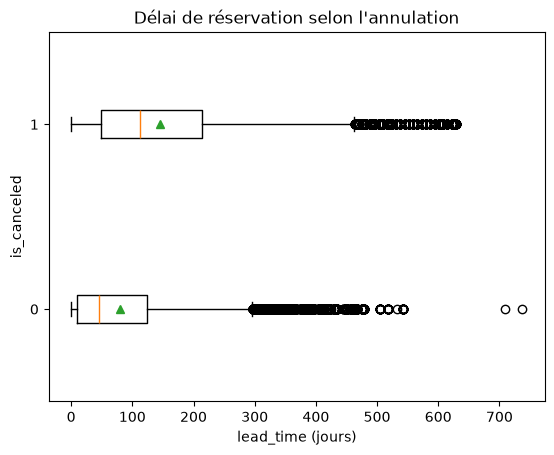

In [89]:
X = "is_canceled"        # variable qualitative : elle définit les groupes à comparer
Y = "lead_time"          # variable quantitative : celle dont on compare la distribution

modalites = data[X].unique()   # valeurs possibles de X (0 et 1)
groupes = []                   # contiendra un groupe de lead_time par valeur de X

for m in modalites:                        # pour chaque valeur (0 puis 1)
    groupes.append(data[data[X]==m][Y])    # garde les lead_time de ce groupe

plt.boxplot(groupes, tick_labels=modalites, vert=False, showmeans=True)   # une boîte à moustaches par groupe
plt.title("Délai de réservation selon l'annulation")
plt.xlabel("lead_time (jours)")
plt.ylabel("is_canceled")
plt.show()

La boîte à moustaches confirme l'écart : la médiane et la moyenne des réservations annulées sont presque deux fois plus élevées. Reste à mesurer la force du lien.

In [90]:
def eta_squared(x, y):                                   # x = variable qualitative, y = variable quantitative
    moyenne_y = y.mean()                                  # moyenne globale de y
    classes = []                                          # informations de chaque groupe
    for classe in x.unique():                             # pour chaque valeur de x
        yi_classe = y[x==classe]                          # les valeurs de y de ce groupe
        classes.append({'ni': len(yi_classe),             # taille du groupe
                        'moyenne_classe': yi_classe.mean()})  # moyenne du groupe
    SCT = sum([(yj-moyenne_y)**2 for yj in y])            # variation totale
    SCE = sum([c['ni']*(c['moyenne_classe']-moyenne_y)**2 for c in classes])   # variation expliquée par les groupes
    return SCE/SCT                                        # part de la variation expliquée = êta carré

eta_squared(data[X], data[Y])

np.float64(0.08592714644629149)

**η² = 0,086 : lien faible à modéré.** Malgré l'écart visible, `lead_time` n'explique qu'une petite partie des annulations. C'est un facteur, mais pas le principal.

### 4.2 `deposit_type`

In [91]:
X = "deposit_type"       # variable qualitative n°1
Y = "is_canceled"        # variable qualitative n°2

cont = pd.crosstab(data[X], data[Y])   # tableau de contingence
cont

is_canceled,0,1
deposit_type,,
No Deposit,74944,29694
Non Refund,93,14493
Refundable,126,36


Les réservations Non Refund sont annulées à 99,4 % (14 493 sur 14 586), contre 28,4 % sans dépôt et 22,2 % avec dépôt remboursable. C'est l'inverse de mon hypothèse de départ.

In [92]:
st_chi2, st_p, st_dof, st_exp = chi2_contingency(cont)   # test du Chi-2 sur le tableau de contingence
st_chi2                                                    # valeur du Chi-2

np.float64(27674.77652161672)

Chi-2 = 27 674,78 : les effectifs observés s'écartent fortement de ceux attendus si les deux variables étaient indépendantes. Cette valeur brute dépend de la taille de l'échantillon ; le coefficient de Cramer la ramène sur une échelle de 0 à 1.

In [93]:
n = cont.sum().sum()                          # nombre total de réservations
phi2 = st_chi2 / n                            # Chi-2 rapporté à la taille de l'échantillon
r, k = cont.shape                             # nombre de lignes et de colonnes du tableau
cramer_v = (phi2 / min(k-1, r-1))**0.5        # coefficient de Cramer, entre 0 et 1
cramer_v

np.float64(0.48146570826098917)

**V de Cramer = 0,48 : lien fort**, le plus fort de toute l'analyse.

Je me demande si ces réservations Non Refund correspondent à des voyages d'affaires. Je regarde par quel canal elles arrivent.

In [94]:
non_refund = data[data['deposit_type'] == 'Non Refund']            # uniquement les réservations non remboursables
non_refund['market_segment'].value_counts(normalize=True) * 100    # canal de réservation, en %

market_segment
Groups           62.882216
Offline TA/TO    34.313725
Corporate         2.289867
Online TA         0.383930
Direct            0.130262
Name: proportion, dtype: float64

97 % d'entre elles viennent de Groups (62,9 %) et d'Offline TA/TO (34,3 %), contre seulement 2,3 % de Corporate. Ce ne sont donc pas des voyages d'affaires, mais plutôt **des réservations de bloc faites par des agences et des tour-opérateurs**.

### 4.3 `market_segment`

In [95]:
X = "market_segment"
Y = "is_canceled"
cont = pd.crosstab(data[X], data[Y])   # canal de réservation × annulation
cont

is_canceled,0,1
market_segment,,
Aviation,185,52
Complementary,646,97
Corporate,4302,992
Direct,10672,1934
Groups,7713,12097
Offline TA/TO,15908,8310
Online TA,35737,20739
Undefined,0,2


Groups annule plus qu'il ne confirme (12 097 annulations pour 7 713 réservations honorées), alors que Direct, Corporate et Online TA sont majoritairement honorés.

In [96]:
st_chi2, st_p, st_dof, st_exp = chi2_contingency(cont)   # test du Chi-2
st_chi2

np.float64(8497.899008752429)

In [97]:
n = cont.sum().sum()
phi2 = st_chi2 / n
r, k = cont.shape
cramer_v = (phi2 / min(k-1, r-1))**0.5   # coefficient de Cramer
cramer_v

np.float64(0.2667958574594181)

Chi-2 = 8 497,90 et **V de Cramer = 0,267 : lien fort** selon la grille, mais nettement moins que `deposit_type`. Le canal de réservation est un facteur important du risque d'annulation.

### 4.4 `customer_type`

In [98]:
X = "customer_type"
Y = "is_canceled"
cont = pd.crosstab(data[X], data[Y])   # type de client × annulation
cont

is_canceled,0,1
customer_type,,
Contract,2814,1262
Group,518,59
Transient,53098,36513
Transient-Party,18733,6389


Les clients individuels (Transient) annulent le plus (40,7 %), devant Contract (31 %) et Transient-Party (25,4 %). Les groupes annulent le moins (10,2 %).

In [99]:
st_chi2, st_p, st_dof, st_exp = chi2_contingency(cont)   # test du Chi-2
st_chi2

np.float64(2221.8015563343592)

In [100]:
n = cont.sum().sum()
phi2 = st_chi2 / n
r, k = cont.shape
cramer_v = (phi2 / min(k-1, r-1))**0.5   # coefficient de Cramer
cramer_v

np.float64(0.13641933638702913)

Chi-2 = 2 221,80 et **V de Cramer = 0,136 : lien modéré.** Le type de client joue, mais moins que le canal de réservation ou le type de dépôt.

### 4.5 `hotel`

In [101]:
X = "hotel"
Y = "is_canceled"
cont = pd.crosstab(data[X], data[Y])   # hôtel × annulation
cont

is_canceled,0,1
hotel,,
City Hotel,46226,33101
Resort Hotel,28937,11122


City Hotel a un taux d'annulation nettement plus élevé (41,7 %) que Resort Hotel (27,8 %).

In [102]:
st_chi2, st_p, st_dof, st_exp = chi2_contingency(cont)   # test du Chi-2
st_chi2

np.float64(2224.73006072985)

In [103]:
n = cont.sum().sum()
phi2 = st_chi2 / n
r, k = cont.shape
cramer_v = (phi2 / min(k-1, r-1))**0.5   # coefficient de Cramer
cramer_v

np.float64(0.1365092123409311)

Chi-2 = 2 224,73 et **V de Cramer = 0,137 : lien modéré**, du même ordre que le type de client.

### 4.6 `total_of_special_requests`

In [104]:
data.groupby('is_canceled')['total_of_special_requests'].mean()   # nombre moyen de demandes spéciales : honorées (0) vs annulées (1)

is_canceled
0    0.714075
1    0.328833
Name: total_of_special_requests, dtype: float64

Les clients qui honorent leur réservation font en moyenne 0,71 demande spéciale, contre 0,33 pour ceux qui annulent : deux fois plus.

In [105]:
X = "is_canceled"
Y = "total_of_special_requests"
eta_squared(data[X], data[Y])   # force du lien entre demandes spéciales et annulation

np.float64(0.05506574488039945)

**η² = 0,055 : lien faible**, mais dans le sens inverse des autres : plus un client fait de demandes, moins il annule. Une demande spéciale traduit un client déjà projeté dans son séjour.

### 4.7 `adr`

In [106]:
data.groupby('is_canceled')['adr'].mean()   # prix moyen par nuit : honorées (0) vs annulées (1)

is_canceled
0     99.989381
1    104.844598
Name: adr, dtype: float64

In [107]:
X = "is_canceled"
Y = "adr"
eta_squared(data[X], data[Y])

np.float64(0.0023709245496687115)

Prix moyen quasi identique (100 € pour les réservations honorées, 105 € pour les annulées). **η² = 0,002 : lien quasi nul.** Le prix ne permet pas de prédire une annulation.

### 4.8 Durée du séjour

In [108]:
X = "is_canceled"
print(eta_squared(data[X], data['stays_in_weekend_nights']))   # nuits de week-end
print(eta_squared(data[X], data['stays_in_week_nights']))      # nuits en semaine

3.098842543237282e-06
0.0006140040600041404


η² ≈ 0,000003 pour les nuits de week-end (affiché `3.1e-06`, c'est-à-dire 3,1 × 10⁻⁶) et 0,0006 pour les nuits en semaine : **aucun lien**. La durée du séjour n'influence pas l'annulation.

### 4.9 Récapitulatif

| Variable | Méthode | Coefficient | Force du lien |
|---|---|---|---|
| `deposit_type` | Chi-2 / Cramer | 0,481 | Fort |
| `market_segment` | Chi-2 / Cramer | 0,267 | Fort |
| `hotel` | Chi-2 / Cramer | 0,137 | Modéré |
| `customer_type` | Chi-2 / Cramer | 0,136 | Modéré |
| `lead_time` | ANOVA / η² | 0,086 | Faible à modéré |
| `total_of_special_requests` | ANOVA / η² | 0,055 | Faible (sens inverse) |
| `adr` | ANOVA / η² | 0,002 | Quasi nul |
| `stays_in_week_nights` | ANOVA / η² | 0,0006 | Quasi nul |
| `stays_in_weekend_nights` | ANOVA / η² | ≈ 0 | Quasi nul |

## 5. Conclusion et recommandations

L'analyse fait ressortir deux profils de risque bien différents.

### Profil 1 : les réservations de bloc des agences
- Les réservations Non Refund annulent à 99,4 %, et 97 % d'entre elles viennent de Groups ou d'Offline TA/TO.
- Comme le dépôt n'est pas remboursable, l'hôtel encaisse l'argent : ce n'est pas une perte de vente, mais un **manque à gagner**. La chambre reste bloquée alors qu'elle aurait pu être revendue, et aucune consommation n'a lieu sur place.
- **Recommandation : une liste d'attente proactive.** Quand l'hôtel affiche complet à cause d'un bloc Non Refund, proposer au client de dernière minute de le recontacter en priorité dès qu'une chambre se libère.

### Profil 2 : le client individuel qui se désengage
- Les réservations annulées ont été faites presque deux fois plus tôt (145 jours contre 80).
- Les clients individuels (Transient) annulent à 40,7 %, contre 10,2 % pour les groupes.
- Les clients qui viennent font deux fois plus de demandes spéciales (0,71 contre 0,33).
- **Recommandation 1 : provoquer l'engagement**, en demandant systématiquement au client s'il a une demande spéciale dès la réservation. Attention : c'est une corrélation, pas une preuve de cause à effet. Il faudrait le tester en conditions réelles avant de généraliser.
- **Recommandation 2 : relancer les réservations faites longtemps à l'avance**, avec un mail de confirmation à mi-parcours pour vérifier que le client vient toujours, et en profiter pour proposer des options pour son séjour.

### Autres enseignements
- City Hotel annule plus que Resort Hotel (41,7 % contre 27,8 %).
- Le prix et la durée du séjour n'ont aucun lien avec l'annulation.
- Côté données : un identifiant unique de réservation permettrait de traiter les 31 994 doublons.

### Limite de l'analyse
Chaque variable a été testée seule face aux annulations, jamais en combinaison avec les autres. Une partie de l'effet de `lead_time` pourrait par exemple venir de `deposit_type`. La suite logique serait un modèle prédictif qui croise toutes ces variables à la fois.